In [80]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
from scipy.signal import find_peaks
import glob
from mpl_toolkits.axes_grid1 import Divider, Size


sys.path.insert(0, "./../../Python/cellular_cycle")
sys.path.insert(0, "./../../Python/figures")

import fracprolif as fp

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction

In [76]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')
IMT_DATADIR = "../../Data/cell_cycle_timing"

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

SAVEFILES = True
OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [72]:
condition = "55 kPa erlotinib"

In [28]:
IMT_df = pd.read_csv(Path(SAVE_DIR / f'IMTs_{condition}_cycdi_500_0_4.csv'), header=None)

In [30]:
all_IMTs = IMT_df[0].tolist()

In [31]:
len(all_IMTs)

558

In [38]:
file_location = os.path.join(IMT_DATADIR,'IMTs_55 kPa erlotinib_param_orig.csv')
filepaths = glob.glob(file_location)
filepaths.sort()
print(filepaths)

['../../Data/cell_cycle_timing\\IMTs_55 kPa erlotinib_param_orig.csv']


In [39]:
IMTs = []
for f in filepaths:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

In [40]:
IMTs

[     3.979999999999999716e+01
 0                        33.9
 1                        22.5
 2                        27.2
 3                        20.5
 4                        29.6
 ..                        ...
 293                      46.1
 294                      21.0
 295                      20.2
 296                      21.0
 297                      21.8
 
 [298 rows x 1 columns]]

In [43]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian

In [44]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic

In [45]:
from math import log10, floor
def round_sig(x, sig=2):
    return round(x, sig-int(floor(log10(abs(x))))-1)

def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-9
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

# def logl_emg2v2(log_par, data):
#     l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
#     eps = 10e-12
#     return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

def logl_emg2v2(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-12
    temg2 = list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w))
    emg2 = [x + eps for x in temg2]
    ln_em2 = np.log(emg2)
    return ln_em2.sum()

def calc_aicc(AIC, num_params, samp_size):
    aicc = AIC + (2*num_params*(num_params+1)/(samp_size-num_params-1))
    return aicc

def calc_aicp(AICs):
    aicp = [math.exp((min(AICs)-AIC)/2) for AIC in AICs]
    return aicp


def emg_mle_v2(data, log_par, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def emg2_mle_v2(data, log_par2, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def crit(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    
    LL2 = logl_emg2v2(log_par, data)
    negLL2 = -LL2      
    return negLL2

def smooth(y, box_pts):
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    return y_smooth


In [47]:
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

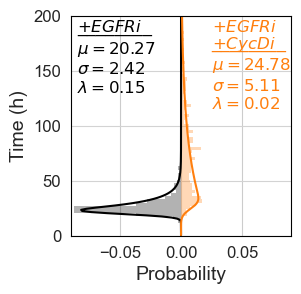

In [82]:
win = 21
pol = 2
size = (3,3)
c1 = "black"
c2 = "tab:orange"
xmin = -0.09
xmax = 0.09
ymin = 0
ymax = 200


params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

BOX = 2.2
LEFT, BOTTOM, RIGHT, TOP = 0.70, 0.55, 0.12, 0.12   # margins in inches

figW = LEFT + BOX + RIGHT
figH = BOTTOM + BOX + TOP
fig = plt.figure(figsize=(figW, figH))
fig.set_layout_engine('none')

h = [Size.Fixed(LEFT),   Size.Fixed(BOX)]
v = [Size.Fixed(BOTTOM), Size.Fixed(BOX)]
div = Divider(fig, (0, 0, 1, 1), h, v, aspect=False)
axes = fig.add_axes(div.get_position(), axes_locator=div.new_locator(nx=1, ny=1))

centers = np.arange(0.5, 200.5, 1)
data = np.array(IMTs)
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,201,3), density=True)
out = axes.stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes.plot(fitted_curve, centers, color=c1)
axes.set_xlim([xmin, xmax])
axes.set_ylim([ymin, ymax])
axes.grid(color='lightgray', axis='y')
axes.text(-0.085, 130, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1, size=12)

axes.text(-0.085, 185, r'${+EGFRi}$', fontsize=12, color=c1)
axes.text(-0.085, 185, '________', fontsize=12, color=c1)


data = np.array(all_IMTs)
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,201,3), density=True)
out = axes.stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes.plot(fitted_curve, centers, color=c2)
axes.set_xlim([xmin, xmax])
axes.set_ylim([ymin, ymax])
axes.grid(color='lightgray', axis='y')
axes.text(0.025, 115, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2, size=12)
axes.text(0.025, 185, r'${+EGFRi}$', fontsize=12, color=c2)
axes.text(0.025, 170, r'${+CycDi}$', fontsize=12, color=c2)
axes.text(0.025, 170, '________', fontsize=12, color=c2)
axes.set_xlabel('Probability')
axes.set_ylabel('Time (h)')

filepath = Path(SAVE_DIR,'fig7b_imts.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)